<a href="https://colab.research.google.com/github/cauavorpagel/pcd-aulas-iniciais/blob/main/TrabalhoWebscraping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Análise de Produtos Oficiais da Franquia Godzilla (godzilla.com)

In [ ]:
!pip install -q google-colab-selenium beautifulsoup4 pandas numpy

In [ ]:
import google_colab_selenium as gs
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **Definição do problema:**

*   **apresentar o tema escolhido:**

1.  Análise de estratégia de preços e acessibilidade do Mercado Oficial de Colecionáveis e Produtos Geek (Godzilla Official Store — godzilla.com).

*   **explicar qual problema ou questão será investigado:**
1.   A precificação no mercado de colecionáveis oficiais frequentemente equilibra itens de alto valor monetário e itens de entrada.
2.   Qual é a estrutura de precificação praticada pela loja oficial do Godzilla e até que ponto o catálogo é comercialmente acessível para consumidores de diferentes faixas de renda?
3.   Como os preços estão distribuídos ao longo do catálogo?
4.   Qual a proporção de produtos considerados "Premium/Colecionador" em relação aos produtos "Acessíveis"?
5.   Como a presença de itens de luxo impacta a média geral do catálogo em comparação com a mediana?

*   **definir quais informações pretende obter a partir dos dados:**
1.  Métricas de Centralidade e Dispersão:
O preço médio, a mediana e o desvio padrão do catálogo em dólar e a conversão estimada para reais.
2.  Segmentação e Categorização Comercial:
Quantidade e percentual exato de produtos divididos em 3 categorias estratégicas: Acessível, Intermediário e Premium/Colecionador.
3.  Proporção de Itens Acima da Média:
Aplicação de máscaras booleanas do NumPy para quantificar exatamente quantos produtos estão acima da média geral da loja, identificando o peso do segmento premium.
4.  Acessibilidade para o Consumidor Brasileiro:
Identificação do volume de produtos de entrada que custam abaixo da mediana e que permanecem na faixa acessível (ex: abaixo de R$ 200,00), permitindo avaliar se a loja atende ao público geral ou se é restrita a grandes colecionadores.
5.  Comportamento da Distribuição Visual:
Mapeamento visual para identificar outliers e verificar a assimetria na distribuição dos preços.





In [ ]:
navegador = gs.Chrome() # abre uma instância do Chrome no servidor
url = "https://godzilla.com/collections/new"
navegador.get(url) # diz para a instância entrar no link passado

<IPython.core.display.Javascript object>

In [ ]:
html_carregado = navegador.page_source # copia todo o HTML da página
navegador.quit()
soup = BeautifulSoup(html_carregado, "html.parser") # reestrutura o HTML

In [ ]:
produtos_encontrados = []
elementos = soup.find_all(['div', 'li', 'a']) # procura as tags com os dados a serem coletados

In [ ]:
for elem in elementos:
    texto = elem.get_text(separator=" | ", strip=True)

    if "$" in texto and "Add To Cart" in texto:
        partes = texto.split(" | ")
        nome = partes[0]

        preco = [p for p in partes if "$" in p][0]

        produtos_encontrados.append({
            "Produto": nome,
            "Preco_Texto": preco
        })

In [ ]:
df = pd.DataFrame(produtos_encontrados) # pega os dados retirados na raspagem e junta tudo em um DataFrame

In [ ]:
print("---| RESULTADO DA EXTRAÇÃO |---")
print(f"Total de produtos encontrados: {len(df)}")
print(df.head)

---| RESULTADO DA EXTRAÇÃO |---
Total de produtos encontrados: 129
<bound method NDFrame.head of                                                Produto Preco_Texto
0                                         New Arrivals      $34.99
1                                         New Arrivals      $34.99
2                                         New Arrivals      $34.99
3    Godzilla (2026) First Look Ver. Movie Monster ...      $34.99
4    Godzilla (2026) First Look Ver. Movie Monster ...      $34.99
..                                                 ...         ...
124                 Godzilla Skeleton Aquarium Bubbler      $74.99
125  Movie Monster Series Megaguirus Odaiba Battle ...      $33.00
126  Movie Monster Series 'Operation Jet Jaguar' Ki...      $42.00
127         Criterion Collection Godzilla 4K + Blu-Ray      $49.95
128                      Godzilla Tokyo x Haas T-Shirt      $58.00

[129 rows x 2 columns]>


ETAPA 2

In [ ]:
print("\n---| Dimensões do Dataset obtido |---")
print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de atributos: {df.shape[1]}")

print("\n---| Tipos de Dados das colunas |---")
print(df.info())

duplicados = df.duplicated(subset=['Produto']).sum()
print("\n---| Incosistências idenficadas |---")
print("Valores nulos:\n", df.isnull().sum())
print(f"Duplicados: {duplicados}")


---| Dimensões do Dataset obtido |---
Quantidade de registros: 129
Quantidade de atributos: 2

---| Tipos de Dados das colunas |---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Produto      129 non-null    object
 1   Preco_Texto  129 non-null    object
dtypes: object(2)
memory usage: 2.1+ KB
None

---| Incosistências idenficadas |---
Valores nulos:
 Produto        0
Preco_Texto    0
dtype: int64
Duplicados: 89


ETAPA 3

In [144]:
df_limpo = df.drop_duplicates(subset=['Produto']).copy() # cria uma cópia do df, retirando as duplicadas

In [151]:
titulos_invalidos = ["Latest Drops", "Shop All", "View All", "New & Trending", "Featured", "New Arrivals"] # nas primeiras tentativas ele trazia o campo "new products" como um produto por ele se encaixar na filtragem, aqui filtrei para esses campos não serem mais considerados
df_limpo = df_limpo[~df_limpo['Produto'].isin(titulos_invalidos)].copy() # verifica se alguma das filtragem acima bate e gera uma nova copia limpa para não dar erro futuramente

In [152]:
def converter_preco_para_float(texto): # transmorma o valor do produto(que está em texto no DF) em um valore decimal
    if pd.isna(texto):
        return np.nan
    try:
        texto_limpo = texto.replace('$', '').replace(',', '').strip()
        return float(texto_limpo)
    except ValueError:
        return np.nan

In [153]:
df_limpo['Preco_USD'] = df_limpo['Preco_Texto'].apply(converter_preco_para_float) # gera uma nova coluna onde é armazenado o valor em USD
df_limpo.dropna(subset=['Preco_USD'], inplace=True) # descarta linhas que tenham ficado com valores nulos quebrados

In [154]:
cotacao_usd_brl = 5.00
df_limpo['Preco_BRL'] = np.round(df_limpo['Preco_USD'] * cotacao_usd_brl, 2) # cria uma nova coluna onde armazena os valores em R$

In [155]:
limites = [0, 30, 70, np.inf] # cria um Array com os limites delimitados para considerar produtos de acordo com o preço
rotulos = ['Acessível (<$30)', 'Intermediário ($30-$70)', 'Premium (>$70)']
df_limpo['Categoria_Preco'] = pd.cut(df_limpo['Preco_USD'], bins=limites, labels=rotulos) # adiciona em cada linha de produto a rótulo de acessibilidade do produto

In [156]:
print("---| DATASET TRATADO E PREPARADO |---")
print(df_limpo[['Produto', 'Preco_USD', 'Preco_BRL', 'Categoria_Preco']])

---| DATASET TRATADO E PREPARADO |---
                                              Produto  Preco_USD  Preco_BRL  \
3   Godzilla (2026) First Look Ver. Movie Monster ...      34.99     174.95   
5   Nendoroid Godzilla (2016) Second Form & Bonus ...      55.99     279.95   
6   Santa Cruz Godzilla Destroyer Recolor Skateboa...     125.00     625.00   
7   Santa Cruz Godzilla Hand Popsicle Skateboard Deck      79.95     399.75   
8    Santa Cruz Roskopp Skateboard Deck - Red Variant      99.95     499.75   
9          Godzilla vs. Santa Cruz Black Snapback Hat      27.95     139.75   
10  Santa Cruz Shin Godzilla Knox Firepit Purple S...      99.95     499.75   
11             Godzilla vs. Santa Cruz Sticker 4-Pack       9.95      49.75   
12                                          JXSDF Hat      25.00     125.00   
13               Destroy All Monsters Vintage T-Shirt      32.00     160.00   
14              Godzilla Battle Snap Monster Blindbag       6.90      34.50   
15            

ETAPA 4

In [ ]:
vetor_precos_usd = df_limpo['Preco_USD'].to_numpy() # converte a coluna (Series) do Pandas diretamente em uma estrutura de dados de matriz/vetor do NumPy
vetor_precos_brl = df_limpo['Preco_BRL'].to_numpy() # Exibe o tipo de dado homogêneo armazenado dentro do vetor NumPy

print("---| CARACTERÍSTICAS DOS VETORES NUMPY |---")
print(f"Tipo de dado (dtype): {vetor_precos_usd.dtype}")
print(f"Formato do vetor (shape): {vetor_precos_usd.shape}\n")

print("---| CARACTERÍSTICAS DOS VETORES NUMPY |---")
print(f"Tipo de dado (dtype): {vetor_precos_brl.dtype}")
print(f"Formato do vetor (shape): {vetor_precos_brl.shape}\n")

---| CARACTERÍSTICAS DOS VETORES NUMPY |---
Tipo de dado (dtype): float64
Formato do vetor (shape): (40,)

---| CARACTERÍSTICAS DOS VETORES NUMPY |---
Tipo de dado (dtype): float64
Formato do vetor (shape): (40,)



In [ ]:
media_usd = np.mean(vetor_precos_usd)
mediana_usd = np.median(vetor_precos_usd)
desvio_padrao_usd = np.std(vetor_precos_usd)
menor_preco_usd = np.min(vetor_precos_usd)
maior_preco_usd = np.max(vetor_precos_usd)

print("---| ESTATÍSTICAS GERAIS DO CATÁLOGO (USD) |---")
print(f"Preço Médio: ${media_usd:.2f}")
print(f"Mediana dos Preços: ${mediana_usd:.2f}")
print(f"Desvio Padrão: ${desvio_padrao_usd:.2f}")
print(f"Menor Preço Encontrado: ${menor_preco_usd:.2f}")
print(f"Maior Preço Encontrado: ${maior_preco_usd:.2f}\n")

media_brl = np.mean(vetor_precos_brl)
mediana_brl = np.median(vetor_precos_brl)
desvio_padrao_brl = np.std(vetor_precos_brl)
menor_preco_brl = np.min(vetor_precos_brl)
maior_preco_brl = np.max(vetor_precos_brl)

print("---| ESTATÍSTICAS GERAIS DO CATÁLOGO (BRL) |---")
print(f"Preço Médio: R${media_brl:.2f}")
print(f"Mediana dos Preços: R${mediana_brl:.2f}")
print(f"Desvio Padrão: R${desvio_padrao_brl:.2f}")
print(f"Menor Preço Encontrado: R${menor_preco_brl:.2f}")
print(f"Maior Preço Encontrado: R${maior_preco_brl:.2f}\n")

---| ESTATÍSTICAS GERAIS DO CATÁLOGO (USD) |---
Preço Médio: $46.79
Mediana dos Preços: $39.00
Desvio Padrão: $32.37
Menor Preço Encontrado: $6.90
Maior Preço Encontrado: $149.99

---| ESTATÍSTICAS GERAIS DO CATÁLOGO (BRL) |---
Preço Médio: R$233.93
Mediana dos Preços: R$195.00
Desvio Padrão: R$161.84
Menor Preço Encontrado: R$34.50
Maior Preço Encontrado: R$749.95



In [ ]:
filtro_entrada = df_limpo[(df_limpo['Preco_BRL'] < 200.0) & (df_limpo['Preco_USD'] <= mediana_usd)]

print("---| AMOSTRAMENTO DE PRODUTOS DE ENTRADA (Média/Baixa Custo) |---")
print(filtro_entrada[['Produto', 'Preco_USD', 'Preco_BRL']].head(10))
print(f"Total de opções de entrada identificadas: {len(filtro_entrada)}\n")

---| AMOSTRAMENTO DE PRODUTOS DE ENTRADA (Média/Baixa Custo) |---
                                              Produto  Preco_USD  Preco_BRL
0                                        New Arrivals      34.99     174.95
3   Godzilla (2026) First Look Ver. Movie Monster ...      34.99     174.95
9          Godzilla vs. Santa Cruz Black Snapback Hat      27.95     139.75
11             Godzilla vs. Santa Cruz Sticker 4-Pack       9.95      49.75
12                                          JXSDF Hat      25.00     125.00
13               Destroy All Monsters Vintage T-Shirt      32.00     160.00
14              Godzilla Battle Snap Monster Blindbag       6.90      34.50
15                        Mothra (1996) Black T-Shirt      28.00     140.00
16  Godzilla Card Game Sleeve & Card Set "Ink-Brus...      39.00     195.00
17  Giant Monsters Clash at Osaka Castle Jigsaw Pu...      24.00     120.00
Total de opções de entrada identificadas: 24



In [ ]:
agrupado_categorias = df_limpo.groupby('Categoria_Preco', observed=False).agg(
    Quantidade=('Preco_USD', 'count'),
    Preco_Medio_USD=('Preco_USD', 'max'),
    Preco_Medio_BRL=('Preco_BRL', 'max'),
    Maior_Preco_USD=('Preco_USD', 'max')
).reset_index()

print("---| RESUMO AGRUPADO POR CATEGORIA COMERCIAL |---")
print(agrupado_categorias)

---| RESUMO AGRUPADO POR CATEGORIA COMERCIAL |---
           Categoria_Preco  Quantidade  Preco_Medio_USD  Preco_Medio_BRL  \
0         Acessível (<$30)          12            28.00           140.00   
1  Intermediário ($30-$70)          21            58.00           290.00   
2           Premium (>$70)           7           149.99           749.95   

   Maior_Preco_USD  
0            28.00  
1            58.00  
2           149.99  


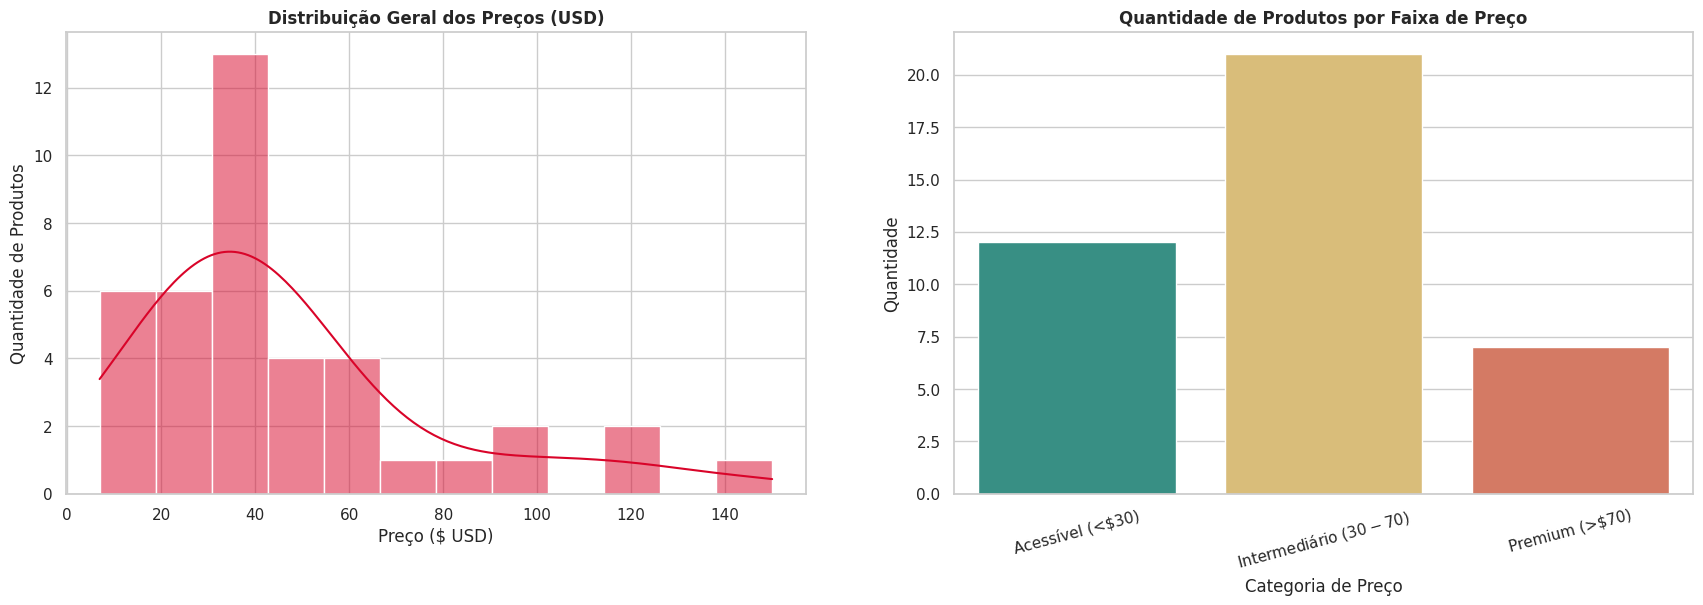

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(21, 6))

sns.histplot(df_limpo['Preco_USD'], kde=True, ax=axes[0], color='#d90429', bins=12)
axes[0].set_title('Distribuição Geral dos Preços (USD)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Preço ($ USD)')
axes[0].set_ylabel('Quantidade de Produtos')


sns.countplot(
    data=df_limpo,
    x='Categoria_Preco',
    ax=axes[1],
    palette=['#2a9d8f', '#e9c46a', '#e76f51'],
    hue='Categoria_Preco',
    legend=False
)
axes[1].set_title('Quantidade de Produtos por Faixa de Preço', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Categoria de Preço')
axes[1].set_ylabel('Quantidade')
axes[1].tick_params(axis='x', rotation=15)